In [ ]:
import os
import pandas as pd
from tqdm import tqdm

DATASET_DIR = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
CONCEPTS_CSV_PATH = "/content/drive/MyDrive/EgMM-Corpus/concepts.csv"

print("🔍 --- بدء فحص وقراءة الملفات الحقيقية --- \n")

if os.path.exists(CONCEPTS_CSV_PATH):
    concepts_df = pd.read_csv(CONCEPTS_CSV_PATH)
    concept_mapping = dict(zip(concepts_df['id'].astype(str), concepts_df['Concept']))
    print(f"✅ تم قراءة concepts.csv بنجاح! تم العثور على {len(concept_mapping)} أثر ومفهوم.")
else:
    print(f"❌ خطأ: مش قادر ألاقي ملف الـ CSV في المسار ده: {CONCEPTS_CSV_PATH}")

if os.path.exists(DATASET_DIR):
    all_folders = os.listdir(DATASET_DIR)
    print(f"✅ تم العثور على فولدر الـ Dataset الرئيسي وبيرجع {len(all_folders)} عنصر.")

    total_images_found = 0
    total_md_found = 0
    sample_printed = False

    for concept_id in all_folders:
        concept_path = os.path.join(DATASET_DIR, concept_id)

        if os.path.isdir(concept_path):

            concept_name = concept_mapping.get(str(concept_id), "Unknown Concept")

            bg_path = os.path.join(concept_path, "background.md")
            if os.path.exists(bg_path):
                total_md_found += 1

            images_in_folder = [f for f in os.listdir(concept_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            total_images_found += len(images_in_folder)

            if not sample_printed and len(images_in_folder) > 0:
                print(f"\n👀 عينة لقراءة أول مجلد تم العثور عليه:")
                print(f" - رقم المجلد (Concept ID): {concept_id}")
                print(f" - اسم الأثر في الـ CSV: {concept_name}")
                print(f" - حالة ملف الـ background.md: {'موجود ومقروء ✅' if os.path.exists(bg_path) else 'مش موجود ❌'}")
                print(f" - عدد الصور المكتشفة جوه المجلد ده: {len(images_in_folder)} صور (مثل: {images_in_folder[0]}) ")
                print("-" * 40 + "\n")
                sample_printed = True

    print("📊 --- الخلاصة التقرير النهائي للقراءة ---")
    print(f"🔹 إجمالي مجلدات الآثار المكتشفة فعلياً: {len([d for d in all_folders if os.path.isdir(os.path.join(DATASET_DIR, d))])}")
    print(f"🔹 إجمالي ملفات background.md المقروءة: {total_md_found}")
    print(f"🔹 إجمالي عدد الصور المكتشفة في كل المجلدات: {total_images_found} صورة.")

else:
    print(f"❌ خطأ حرج: المجلد الرئيسي {DATASET_DIR} مش موجود برضه! تأكدي من طريقة كتابة اسمه الحقيقي في Colab.")

🔍 --- بدء فحص وقراءة الملفات الحقيقية --- 

✅ تم قراءة concepts.csv بنجاح! تم العثور على 333 أثر ومفهوم.
✅ تم العثور على فولدر الـ Dataset الرئيسي وبيرجع 320 عنصر.

👀 عينة لقراءة أول مجلد تم العثور عليه:
 - رقم المجلد (Concept ID): 0
 - اسم الأثر في الـ CSV: Bab al-Nasr (Cairo)
 - حالة ملف الـ background.md: موجود ومقروء ✅
 - عدد الصور المكتشفة جوه المجلد ده: 20 صور (مثل: 15.png) 
----------------------------------------

📊 --- الخلاصة التقرير النهائي للقراءة ---
🔹 إجمالي مجلدات الآثار المكتشفة فعلياً: 320
🔹 إجمالي ملفات background.md المقروءة: 320
🔹 إجمالي عدد الصور المكتشفة في كل المجلدات: 4654 صورة.


In [2]:

!pip install -q transformers langchain langchain-experimental langchain-community sentence-transformers Pillow torch tqdm pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [56]:
# 1. تثبيت المكتبات
!pip install -q transformers langchain Pillow torch torchvision tqdm pandas

import os
import torch
import pandas as pd
import pickle
from PIL import Image
from transformers import AutoModel, AutoProcessor
#from langchain.text_splitter import RecursiveCharacterTextSplitter
from tqdm import tqdm
from google.colab import drive

# 2. ربط Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
!pip install -q timm transformers langchain-experimental langchain-community sentence-transformers

In [4]:
# تثبيت مكتبة CLIP مباشرة من المصدر
!pip install git+https://github.com/openai/CLIP.git
# تثبيت باقي المكتبات اللي هنحتاجها للـ Semantic Chunking
!pip install -q langchain langchain-experimental langchain-community sentence-transformers

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-9_e0x61r
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-9_e0x61r
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.1 MB/s eta 0:00:00
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369490 sha256=7848c06757042901fe4ec4ae3b96431470c9b4b23010e8d9cd971302cc625f50
  Stored in directory: /tmp/pip-ephem-wheel-cache-jxztgc0c/wheels/35/3e/df/3d24cbfb3b6a06f17a2bfd7d1138900d4365d9028aa8f6e92f
Successfully built clip


In [58]:
import torch
import clip
import os

device = "cuda" if torch.cuda.is_available() else "cpu"


model, preprocess = clip.load("ViT-B/32", device=device)

model_path = "/content/drive/MyDrive/CLIP-FineTuning/egypt_clip_best.pt"

if os.path.exists(model_path):
    print("✅ Found your 'egypt_clip_best.pt' on Drive!")
    checkpoint = torch.load(model_path, map_location=device)

    try:
        if isinstance(checkpoint, dict):
            state_dict = checkpoint.get('state_dict', checkpoint.get('model', checkpoint))
        else:
            state_dict = checkpoint

        model.load_state_dict(state_dict, strict=False)
        print("✨ Success! Your Custom Egypt-CLIP is ready for embedding.")
    except Exception as e:
        print(f"⚠️ Error during loading: {e}")
else:
    print(f" Path not found: {model_path}")
    print("تأكدي أن الملف 'egypt_clip_best.pt' موجود فعلياً داخل فولدر CLIP-FineTuning")

model.eval()

✅ Found your 'egypt_clip_best.pt' on Drive!
✨ Success! Your Custom Egypt-CLIP is ready for embedding.


CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): Sequential(
        (0): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): QuickGELU()
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        )
        (1): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          

In [6]:
import pandas as pd
from langchain_experimental.text_splitter import SemanticChunker
from langchain_community.embeddings import HuggingFaceEmbeddings

print("⏳ Initializing Semantic Chunker...")
embed_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
semantic_splitter = SemanticChunker(embed_model)

PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus"
CSV_PATH = os.path.join(PARENT_PATH, "concepts.csv")
df = pd.read_csv(CSV_PATH)
df['id_str'] = df['id'].astype(int).astype(str)
concept_map = dict(zip(df['id_str'], df['Concept']))

found_paths = {}
for root, dirs, files in os.walk(PARENT_PATH):
    folder_name = os.path.basename(root)
    if folder_name in concept_map:
        found_paths[folder_name] = root

final_dataset = []

for folder_id, full_path in tqdm(found_paths.items(), desc="Processing Egypt-CLIP Data"):
    concept_name = concept_map[folder_id]

    bg_path = os.path.join(full_path, "background.md")
    text_chunks = []
    if os.path.exists(bg_path):
        try:
            with open(bg_path, 'r', encoding='utf-8') as f:
                full_text = f.read()
                if len(full_text.strip()) > 10:

                    docs = semantic_splitter.create_documents([full_text])
                    text_chunks = [doc.page_content for doc in docs]
        except: text_chunks = []

    valid_exts = ('.png', '.jpg', '.jpeg')
    images = [f for f in os.listdir(full_path) if f.lower().endswith(valid_exts)]

    for img_name in images:
        img_path = os.path.join(full_path, img_name)
        try:

            image_input = preprocess(Image.open(img_path)).unsqueeze(0).to(device)
            with torch.no_grad():
                image_features = model.encode_image(image_input)

                emb = image_features / image_features.norm(dim=-1, keepdim=True)

            final_dataset.append({
                "concept_id": folder_id,
                "concept_name": concept_name,
                "semantic_chunks": text_chunks,
                "image_name": img_name,
                "embedding": emb.cpu().numpy().flatten()
            })
        except: continue

save_file = "/content/drive/MyDrive/Egypt_CLIP_Semantic_Dataset.pkl"
with open(save_file, 'wb') as f:
    pickle.dump(final_dataset, f)

print(f"\n✨ تم بنجاح! تم إنشاء قاعدة بيانات تحتوي على {len(final_dataset)} صورة مرتبطة بنصوص مقسمة دلالياً.")

/tmp/ipykernel_1197/2481538095.py:2: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker


⏳ Initializing Semantic Chunker...


/tmp/ipykernel_1197/2481538095.py:6: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embed_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

... (8 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Processing Egypt-CLIP Data: 100%|██████████| 320/320 [30:26<00:00,  5.71s/it]


✨ تم بنجاح! تم إنشاء قاعدة بيانات تحتوي على 4654 صورة مرتبطة بنصوص مقسمة دلالياً.


In [59]:
def identify_ancient_monument(query_image_path, top_k=1):

    query_image = Image.open(query_image_path).convert('RGB')
    query_input = preprocess(query_image).unsqueeze(0).to(device)


    with torch.no_grad():
        query_features = model.encode_image(query_input)
        query_features /= query_features.norm(dim=-1, keepdim=True)
        query_emb = query_features.cpu().numpy().flatten()

    all_embeddings = np.array([item['embedding'] for item in final_dataset])
    similarities = cosine_similarity([query_emb], all_embeddings)[0]

    best_match_idx = np.argmax(similarities)
    best_match = final_dataset[best_match_idx]
    score = similarities[best_match_idx]


    print(f"\n🔍 Result: This is likely '{best_match['concept_name']}'")
    print(f"📊 Confidence Score: {score:.2%}")


    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(query_image)
    plt.title("Tourist Photo")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus"
    concept_id = str(best_match['concept_id'])
    target_folder = os.path.join(PARENT_PATH, concept_id)

    match_img_path = None
    if os.path.exists(target_folder):
        valid_images = [f for f in os.listdir(target_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
        if valid_images:
            match_img_path = os.path.join(target_folder, valid_images[0])

    if match_img_path:
        plt.imshow(Image.open(match_img_path))
        plt.title(f"Matched: {best_match['concept_name']}")
    else:
        plt.text(0.5, 0.5, f"Image Not Found\nID: {concept_id}", ha='center', va='center', color='red')

    plt.axis('off')
    plt.show()


✅ Identification Success!
🏛️ Landmark: Umm Kulthum Museum
📊 Confidence: 57.79%
------------------------------


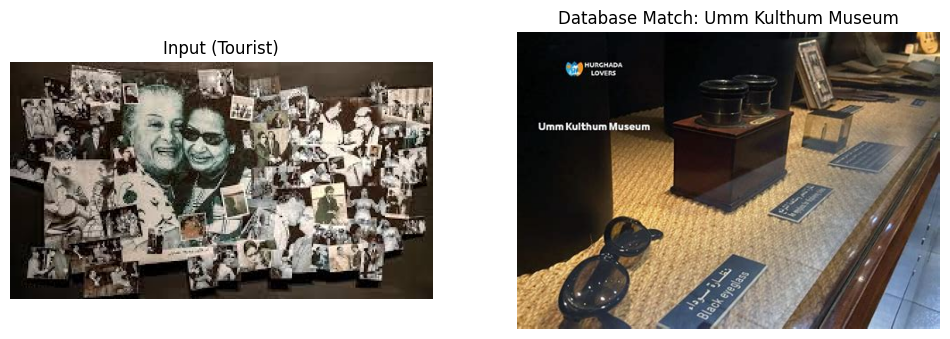

In [60]:
import os
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

def identify_ancient_monument(query_image_path):
    try:
        # 1. معالجة صورة السائح
        query_image = Image.open(query_image_path).convert('RGB')
        query_input = preprocess(query_image).unsqueeze(0).to(device)

        # 2. استخراج الـ Embedding لصورة السائح
        with torch.no_grad():
            query_features = model.encode_image(query_input)
            query_features /= query_features.norm(dim=-1, keepdim=True)
            query_emb = query_features.cpu().numpy().flatten()

        # 3. حساب التشابه مع قاعدة البيانات
        all_embeddings = np.array([item['embedding'] for item in final_dataset])
        similarities = cosine_similarity([query_emb], all_embeddings)[0]

        best_match_idx = np.argmax(similarities)
        best_match = final_dataset[best_match_idx]
        score = similarities[best_match_idx]

        # 4. طباعة المعلومات في الكونسول
        print(f"\n✅ Identification Success!")
        print(f"🏛️ Landmark: {best_match['concept_name']}")
        print(f"📊 Confidence: {score:.2%}")
        print("-" * 30)

        # 5. عرض الصور
        plt.figure(figsize=(12, 6))

        # صورة السائح
        plt.subplot(1, 2, 1)
        plt.imshow(query_image)
        plt.title("Input (Tourist)")
        plt.axis('off')

        # صورة قاعدة البيانات (Match)
        plt.subplot(1, 2, 2)
        PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
        concept_id = str(best_match['concept_id'])
        target_folder = os.path.join(PARENT_PATH, concept_id)

        match_img_path = None
        if os.path.exists(target_folder):
            # بنجيب أول صورة متاحة في المجلد أيًا كان اسمها
            valid_images = [f for f in os.listdir(target_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
            if valid_images:
                match_img_path = os.path.join(target_folder, valid_images[0])

        if match_img_path:
            plt.imshow(Image.open(match_img_path))
            plt.title(f"Database Match: {best_match['concept_name']}")
        else:
            plt.text(0.5, 0.5, f"Match Found: {best_match['concept_name']}\n(Image File Path Error)",
                     ha='center', va='center', color='orange', fontsize=10)

        plt.axis('off')
        plt.show()

    except Exception as e:
        print(f"❌ Error during execution: {e}")

# --- تشغيل الدالة فوراً ---
# تأكدي إن الصورة دي مرفوعة عندك في ملفات الكولاب
test_image_path = "/content/download (2).jpeg"

if os.path.exists(test_image_path):
    identify_ancient_monument(test_image_path)
else:
    print(f"⚠️ تنبيه: الصورة {test_image_path} مش موجودة، ارفعيها الأول.")


✅ Identification Success!
🏛️ Landmark: Umm Kulthum Museum
📊 Confidence: 57.79%
--------------------------------------------------
📜 Description:
 # Wikipedia: Umm Kulthum Museum Om Kalthoum Museum is a biographical museum on
Roda Island, Cairo, Egypt. The Om Kalthoum Museum is dedicated to Umm Kulthum,
or Om Kalthoum, the famous Egyptian singer, songwriter, and actress. The museum
is located in the Monastirli Palace, which dates from 1851. References External
links  Media related to Umm Kulthum Museum at Wikimedia Commons Official website
# Britannica: The Kawkab al-Sharq Museum was established in Cairo in 2001 by the
Egyptian government to celebrate the life and accomplishments of the singer Umm
Kulthum. Umm Kulthum, also known as "Star of the East" (Kawkab al-Sharq), was an
Egyptian singer who captivated Arab audiences for half a century and was one of
the most famous Arab singers and public figures of the 20th century. ##
Britannica: Umm Kulthum | Biography, Songs, & Facts | Britan

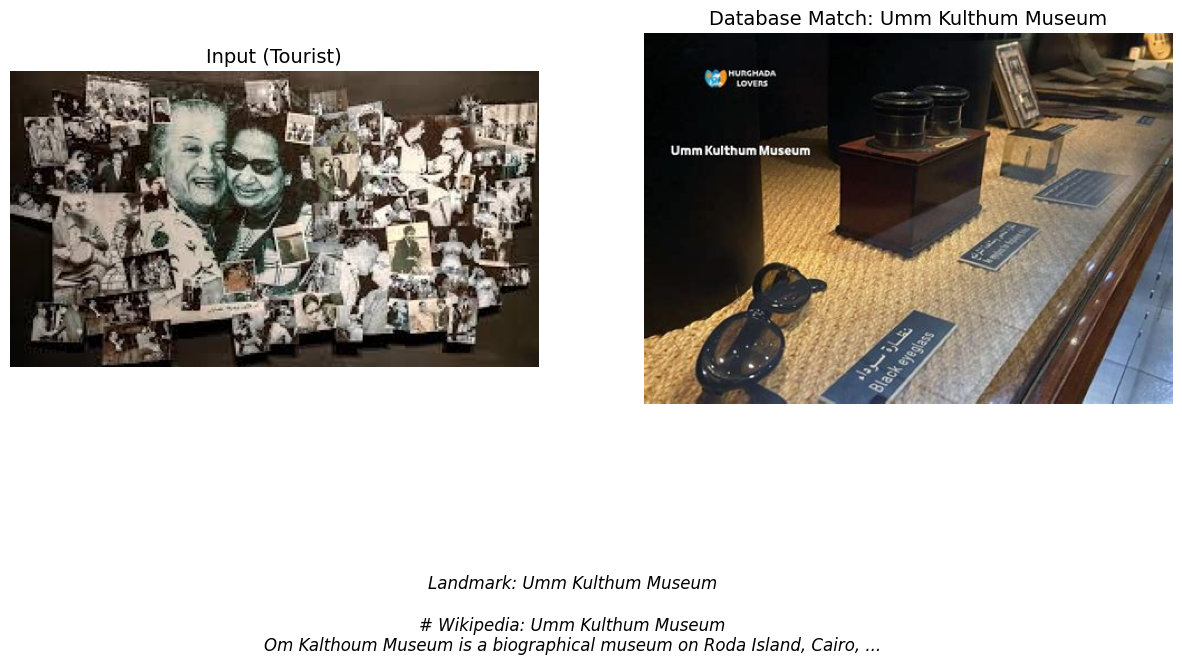

In [68]:
import os
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import textwrap # مكتبة عشان تنسيق النصوص الطويلة

def identify_ancient_monument(query_image_path):
    try:
        # 1. معالجة صورة السائح
        query_image = Image.open(query_image_path).convert('RGB')
        query_input = preprocess(query_image).unsqueeze(0).to(device)

        # 2. استخراج الـ Embedding
        with torch.no_grad():
            query_features = model.encode_image(query_input)
            query_features /= query_features.norm(dim=-1, keepdim=True)
            query_emb = query_features.cpu().numpy().flatten()

        # 3. حساب التشابه
        all_embeddings = np.array([item['embedding'] for item in final_dataset])
        similarities = cosine_similarity([query_emb], all_embeddings)[0]

        best_match_idx = np.argmax(similarities)
        best_match = final_dataset[best_match_idx]
        score = similarities[best_match_idx]

        # 4. طباعة النتائج في الكونسول
        print(f"\n✅ Identification Success!")
        print(f"🏛️ Landmark: {best_match['concept_name']}")
        print(f"📊 Confidence: {score:.2%}")
        print("-" * 50)

        # --- إضافة الوصف هنا ---
        print("📜 Description:")
        if 'semantic_chunks' in best_match and best_match['semantic_chunks']:
            # بناخد أول جزء من الوصف وننسقه عشان ميبقاش سطر طويل أوي
            full_desc = " ".join(best_match['semantic_chunks'])
            wrapped_desc = textwrap.fill(full_desc, width=80)
            print(wrapped_desc)
        else:
            print("No description available for this monument.")
        print("-" * 50)

        # 5. عرض الصور
        plt.figure(figsize=(15, 8))

        # صورة السائح
        plt.subplot(1, 2, 1)
        plt.imshow(query_image)
        plt.title("Input (Tourist)", fontsize=14)
        plt.axis('off')

        # صورة قاعدة البيانات
        plt.subplot(1, 2, 2)
        PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
        concept_id = str(best_match['concept_id'])
        target_folder = os.path.join(PARENT_PATH, concept_id)

        match_img_path = None
        if os.path.exists(target_folder):
            valid_images = [f for f in os.listdir(target_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
            if valid_images:
                match_img_path = os.path.join(target_folder, valid_images[0])

        if match_img_path:
            plt.imshow(Image.open(match_img_path))
            plt.title(f"Database Match: {best_match['concept_name']}", fontsize=14)
        else:
            plt.text(0.5, 0.5, f"Match Found: {best_match['concept_name']}\n(Image Path Error)",
                     ha='center', va='center', color='orange')

        plt.axis('off')

        # إضافة الوصف كعنوان فرعي أسفل الصور (اختياري)
        short_desc = best_match['semantic_chunks'][0][:100] + "..." if best_match['semantic_chunks'] else ""
        plt.suptitle(f"Landmark: {best_match['concept_name']}\n{short_desc}", y=0.05, fontsize=12, style='italic')

        plt.show()

    except Exception as e:
        print(f"❌ Error during execution: {e}")

# --- تشغيل الدالة ---
test_image_path = "/content/download (2).jpeg"
if os.path.exists(test_image_path):
    identify_ancient_monument(test_image_path)


✅ Identification Success!
🏛️ Landmark: Umm Kulthum Museum
📊 Confidence: 57.79%
----------------------------------------
📜 Quick Description:
 # Wikipedia: Umm Kulthum Museum Om Kalthoum Museum is a biographical
museum on Roda Island, Cairo, Egypt. The Om Kalthoum Museum is
dedicated to Umm Kulthum, or Om Kalthoum, the famous Egyptian singer,
songwriter, and actress. The museum is located ...
----------------------------------------


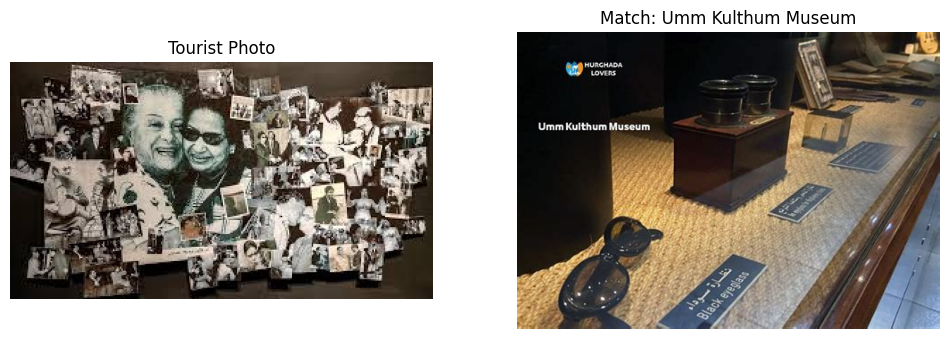

In [69]:
import textwrap

def identify_ancient_monument(query_image_path):
    try:
        # (الجزء الخاص بالمعالجة والـ Embedding والتشابه يظل كما هو دون تغيير)
        query_image = Image.open(query_image_path).convert('RGB')
        query_input = preprocess(query_image).unsqueeze(0).to(device)

        with torch.no_grad():
            query_features = model.encode_image(query_input)
            query_features /= query_features.norm(dim=-1, keepdim=True)
            query_emb = query_features.cpu().numpy().flatten()

        all_embeddings = np.array([item['embedding'] for item in final_dataset])
        similarities = cosine_similarity([query_emb], all_embeddings)[0]

        best_match_idx = np.argmax(similarities)
        best_match = final_dataset[best_match_idx]
        score = similarities[best_match_idx]

        # 4. طباعة النتائج (وصف قصير)
        print(f"\n✅ Identification Success!")
        print(f"🏛️ Landmark: {best_match['concept_name']}")
        print(f"📊 Confidence: {score:.2%}")
        print("-" * 40)

        # --- استخراج وصف قصير جداً (أول 200 حرف مثلاً) ---
        print("📜 Quick Description:")
        if 'semantic_chunks' in best_match and best_match['semantic_chunks']:
            # بناخد أول فقرة بس وبنقصها لو طويلة جداً
            short_desc = best_match['semantic_chunks'][0]
            if len(short_desc) > 250:
                short_desc = short_desc[:250] + "..."

            wrapped_desc = textwrap.fill(short_desc, width=70)
            print(wrapped_desc)
        else:
            print("No description available.")
        print("-" * 40)

        # 5. عرض الصور (يظل كما هو)
        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        plt.imshow(query_image)
        plt.title("Tourist Photo")
        plt.axis('off')

        plt.subplot(1, 2, 2)
        PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
        concept_id = str(best_match['concept_id'])
        target_folder = os.path.join(PARENT_PATH, concept_id)

        # كود جلب الصورة من الدرايف
        match_img_path = None
        if os.path.exists(target_folder):
            valid_images = [f for f in os.listdir(target_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
            if valid_images:
                match_img_path = os.path.join(target_folder, valid_images[0])

        if match_img_path:
            plt.imshow(Image.open(match_img_path))
            plt.title(f"Match: {best_match['concept_name']}")
        else:
            plt.text(0.5, 0.5, "Image Not Found", ha='center', va='center')

        plt.axis('off')
        plt.show()

    except Exception as e:
        print(f"❌ Error: {e}")

# التشغيل
identify_ancient_monument("/content/download (2).jpeg")

In [63]:
import pickle
save_path = '/content/drive/MyDrive/final_dataset_embeddings.pkl'

with open(save_path, 'wb') as f:
    pickle.dump(final_dataset, f)

print(f"✅ تم حفظ الـ Embeddings والبيانات بنجاح في: {save_path}")

✅ تم حفظ الـ Embeddings والبيانات بنجاح في: /content/drive/MyDrive/final_dataset_embeddings.pkl


In [64]:

!pip install -q gradio

import gradio as gr
import os
import numpy as np
import torch
from PIL import Image
import textwrap

def gradio_interface(input_img):
    try:
        query_image = Image.fromarray(input_img).convert('RGB')
        query_input = preprocess(query_image).unsqueeze(0).to(device)

        with torch.no_grad():
            query_features = model.encode_image(query_input)
            query_features /= query_features.norm(dim=-1, keepdim=True)
            query_emb = query_features.cpu().numpy().flatten()

        all_embeddings = np.array([item['embedding'] for item in final_dataset])
        similarities = cosine_similarity([query_emb], all_embeddings)[0]

        best_match_idx = np.argmax(similarities)
        best_match = final_dataset[best_match_idx]
        score = similarities[best_match_idx]

        PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
        concept_id = str(best_match['concept_id'])
        target_folder = os.path.join(PARENT_PATH, concept_id)

        match_img = None
        if os.path.exists(target_folder):
            valid_images = [f for f in os.listdir(target_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
            if valid_images:
                match_img = Image.open(os.path.join(target_folder, valid_images[0]))

        description = "No description available."
        if 'semantic_chunks' in best_match and best_match['semantic_chunks']:
            description = best_match['semantic_chunks'][0]
            if len(description) > 300:
                description = description[:300] + "..."

        return match_img, f"{best_match['concept_name']} ({score:.2%})", description

    except Exception as e:
        return None, "Error", str(e)

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🏛️ سفيرة حضارة - Civilization Ambassador")
    gr.Markdown("ارفع صورة لأي أثر مصري وسيقوم النظام بالتعرف عليه وشرح تاريخه.")

    with gr.Row():
        with gr.Column():
            input_image = gr.Image(label="ارفع صورة الأثر هنا")
            btn = gr.Button("تعرف على الأثر ✨", variant="primary")

        with gr.Column():
            output_image = gr.Image(label="الصورة المطابقة من قاعدة البيانات")
            output_name = gr.Textbox(label="اسم الأثر ونسبة التأكد")
            output_desc = gr.Textbox(label="وصف تاريخي مختصر", lines=5)

    btn.click(fn=gradio_interface, inputs=input_image, outputs=[output_image, output_name, output_desc])

# 3. تشغيل الواجهة
demo.launch(share=True, debug=True)

/tmp/ipykernel_1197/4004627684.py:48: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2a889b43b28c86a29b.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 421, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 56, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1159, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7f81cc46095d68ef8a.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://0c0471f059e2e6d5ac.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://955f177b9fe5d90721.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://929ad59dfe3abd5aed.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://833abc0323f508d253.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://d12027ef05fb531cac.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://2464a4d3835ec7be43.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://ab9955250fa9a5bd38.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://f32eeaefa84903091f.gradio.live
Killing tunnel 127.0.0.1:7861 <> https://2a889b43b28c86a29b.gradio.live


In [14]:
!pip install -q gradio

import gradio as gr
import os
import numpy as np
import torch
from PIL import Image
import textwrap

def gradio_interface(input_img):
    try:
        query_image = Image.fromarray(input_img).convert('RGB')
        query_input = preprocess(query_image).unsqueeze(0).to(device)

        with torch.no_grad():
            query_features = model.encode_image(query_input)
            query_features /= query_features.norm(dim=-1, keepdim=True)
            query_emb = query_features.cpu().numpy().flatten()

        all_embeddings = np.array([item['embedding'] for item in final_dataset])
        similarities = cosine_similarity([query_emb], all_embeddings)[0]

        best_match_idx = np.argmax(similarities)
        best_match = final_dataset[best_match_idx]
        score = similarities[best_match_idx]

        PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
        concept_id = str(best_match['concept_id'])
        target_folder = os.path.join(PARENT_PATH, concept_id)

        match_img = None
        if os.path.exists(target_folder):
            valid_images = [f for f in os.listdir(target_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
            if valid_images:
                match_img = Image.open(os.path.join(target_folder, valid_images[0]))

        # 💡 التعديل هنا فقط لتطويل الوصف وتجميعه بشكل منسق
        description = "No description available."
        if 'semantic_chunks' in best_match and best_match['semantic_chunks']:
            # بناخد أول 4 فقرات من النصوص وبنربطهم ببعض بسطرين فاضيين
            full_chunks = best_match['semantic_chunks'][:4]
            description = "\n\n".join(full_chunks)

            # زودنا الليميت لـ 1500 حرف عشان النص الطويل ميتطلعش مقطوع
            if len(description) > 1500:
                description = description[:1500] + "..."

        return match_img, f"{best_match['concept_name']} ({score:.2%})", description

    except Exception as e:
        return None, "Error", str(e)

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🏛️ سفيرة حضارة - Civilization Ambassador")
    gr.Markdown("ارفع صورة لأي أثر مصري وسيقوم النظام بالتعرف عليه وشرح تاريخه.")

    with gr.Row():
        with gr.Column():
            input_image = gr.Image(label="ارفع صورة الأثر هنا")
            btn = gr.Button("تعرف على الأثر ✨", variant="primary")

        with gr.Column():
            output_image = gr.Image(label="الصورة المطابقة من قاعدة البيانات")
            output_name = gr.Textbox(label="اسم الأثر ونسبة التأكد")
            # 💡 هنا كبرنا عدد الأسطر لـ 12 عشان يعرض الوصف الطويل كله علطول
            output_desc = gr.Textbox(label="الوصف التاريخي", lines=12)

    btn.click(fn=gradio_interface, inputs=input_image, outputs=[output_image, output_name, output_desc])

# 3. تشغيل الواجهة
demo.launch(share=True, debug=True)

/tmp/ipykernel_1197/3497622109.py:53: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://4dbf69ea4539695fab.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 421, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 56, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1159, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://4dbf69ea4539695fab.gradio.live


In [70]:
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-3B-Instruct",
    device_map="auto"
)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [ ]:
!pip install -q gradio

import gradio as gr
import os
import numpy as np
import torch
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity

def gradio_interface(input_img):
    try:
        query_image = Image.fromarray(input_img).convert('RGB')
        query_input = preprocess(query_image).unsqueeze(0).to(device)

        with torch.no_grad():
            query_features = model.encode_image(query_input)
            query_features /= query_features.norm(dim=-1, keepdim=True)
            query_emb = query_features.cpu().numpy().flatten()

        all_embeddings = np.array([item['embedding'] for item in final_dataset])
        similarities = cosine_similarity([query_emb], all_embeddings)[0]

        best_match_idx = np.argmax(similarities)
        best_match = final_dataset[best_match_idx]
        score = similarities[best_match_idx]

        PARENT_PATH = "/content/drive/MyDrive/EgMM-Corpus/conceptImgDataset"
        concept_id = str(best_match['concept_id'])
        target_folder = os.path.join(PARENT_PATH, concept_id)

        match_img = None
        if os.path.exists(target_folder):
            valid_images = [
                f for f in os.listdir(target_folder)
                if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))
            ]

            if valid_images:
                match_img = Image.open(
                    os.path.join(target_folder, valid_images[0])
                )

        # =========================
        # RAG Generation
        # =========================

        generated_description = "No information available."

        if (
            "semantic_chunks" in best_match
            and len(best_match["semantic_chunks"]) > 0
        ):

            context = "\n\n".join(
                best_match["semantic_chunks"][:5]
            )

            prompt = f"""
You are an expert Egyptologist.

Use ONLY the information below.

Context:
{context}

Write a detailed historical description of this Egyptian monument.
"""

            response = generator(
                prompt,
                max_new_tokens=250,
                do_sample=False
            )

            generated_description = response[0]["generated_text"]

            if generated_description.startswith(prompt):
                generated_description = generated_description[len(prompt):].strip()

        return (
            match_img,
            f"{best_match['concept_name']} ({score:.2%})",
            generated_description
        )

    except Exception as e:
        return None, "Error", str(e)


with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("# 🏛️ Civilization Ambassador")
    gr.Markdown(
        "Upload an Egyptian monument image and get an AI-generated description."
    )

    with gr.Row():

        with gr.Column():
            input_image = gr.Image(label="Upload Monument Image")
            btn = gr.Button("Identify Monument ✨")

        with gr.Column():
            output_image = gr.Image(label="Matched Image")
            output_name = gr.Textbox(label="Monument Name")
            output_desc = gr.Textbox(
                label="AI Generated Description",
                lines=15
            )

    btn.click(
        fn=gradio_interface,
        inputs=input_image,
        outputs=[
            output_image,
            output_name,
            output_desc
        ]
    )

demo.launch(share=True, debug=True)

/tmp/ipykernel_1197/4220759475.py:90: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://37e798fceffd7c97e4.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 421, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 56, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1159, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error